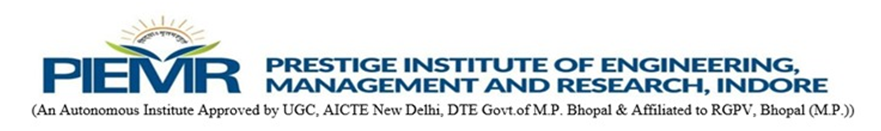

## Step 2: Loading the MNIST Dataset

### What is a Forward Pass?

A forward pass is the process of passing one or more input images through a neural network, layer by layer, to generate predictions. Information flows in one direction: from the input layer to the hidden layer and then to the output layer.

In this experiment, we will build a simple neural network to classify handwritten digits from 0 to 9 using the MNIST dataset. The network contains 784 input features, 128 hidden neurons with ReLU activation, and 10 output neurons with Softmax activation.

Before training the network, we first load the dataset and verify its dimensions. We will initially use randomly initialized weights to test the network's operations. The network will learn to classify digits later through backpropagation and weight updates.

### Load the Dataset

The MNIST dataset contains 70,000 grayscale images of handwritten digits. It is divided into 60,000 training images and 10,000 testing images. Each image has a resolution of 28 × 28 pixels, and each image has a corresponding digit label.

The following code loads the dataset and displays the shapes of the images and labels.

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load the MNIST handwritten digit dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)



Dataset loaded successfully!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


## Step 3: Neural Network Architecture and Parameter Initialization

### Starting Weights: Small and Random, Not Zero

Before a neural network can make predictions, it needs weights and biases. These parameters determine how information flows through the network.

In this experiment, the network has three layers:

- **Input layer:** 784 input features, representing the 28 × 28 pixels of each image.
- **Hidden layer:** 128 neurons using ReLU activation.
- **Output layer:** 10 neurons, representing the digits 0 to 9, using Softmax activation.

### Why Are Weights Initialized Randomly?

The weight matrices are initialized with small random values rather than zeros. If all weights connected to the hidden neurons started with identical values, the neurons could learn identical features because they would receive the same gradients and update in the same way. This problem is called **symmetry**.

Random initialization breaks this symmetry, allowing different neurons to learn different patterns in handwritten digits.

The code uses a scaled random initialization based on the He initialization approach. This helps control the scale of the values passed through the network, particularly when using ReLU activation.

### Why Are Biases Initialized to Zero?

The bias values are initially set to zero. Unlike identical weight initialization, setting all biases to zero does not prevent neurons from learning different features when their incoming weights are initialized randomly.

### Parameter Initialization

The function `init_params()` creates four parameter arrays:

- `W1`: Weights connecting the 784 input features to the 128 hidden neurons.
- `b1`: Biases for the 128 hidden neurons.
- `W2`: Weights connecting the 128 hidden neurons to the 10 output neurons.
- `b2`: Biases for the 10 output neurons.

The random seed is set to 42 so that the random weight values can be reproduced when the same code is run under the same conditions.

In [3]:

# Neural network architecture
INPUT_SIZE = 784
HIDDEN_SIZE = 128
OUTPUT_SIZE = 10

def init_params():
    # Initialize weights with small random values
    W1 = np.random.randn(INPUT_SIZE, HIDDEN_SIZE) * np.sqrt(2.0 / INPUT_SIZE)
    b1 = np.zeros((1, HIDDEN_SIZE))

    W2 = np.random.randn(HIDDEN_SIZE, OUTPUT_SIZE) * np.sqrt(2.0 / HIDDEN_SIZE)
    b2 = np.zeros((1, OUTPUT_SIZE))

    return W1, b1, W2, b2

# Initialize parameters
np.random.seed(42)
W1, b1, W2, b2 = init_params()

print("W1 (input -> hidden):", W1.shape)
print("b1:", b1.shape)
print("W2 (hidden -> output):", W2.shape)
print("b2:", b2.shape)
print()
print("A few starting weight values (W1):",
      np.round(W1[0, :5], 4))


W1 (input -> hidden): (784, 128)
b1: (1, 128)
W2 (hidden -> output): (128, 10)
b2: (1, 10)

A few starting weight values (W1): [ 0.0251 -0.007   0.0327  0.0769 -0.0118]


## Step 4: Activation Functions — ReLU and Softmax

Activation functions help a neural network learn patterns in data. In this experiment, we use ReLU in the hidden layer and Softmax in the output layer.

### 1. ReLU (Rectified Linear Unit)

ReLU is used in the hidden layer. It returns zero for negative input values and keeps positive input values unchanged.

For example, if the input values are `[2.0, -1.0, 0.5]`, ReLU produces `[2.0, 0.0, 0.5]`.

ReLU introduces **nonlinearity** into the network. Without a nonlinear activation function, multiple linear layers would effectively behave like a single linear transformation, limiting the patterns the network could learn.

### 2. Softmax

Softmax is used in the output layer to convert raw scores, also called logits, into probabilities. Each probability lies between 0 and 1, and all probabilities for a sample add up to 1.

In our MNIST classifier, the output layer contains 10 neurons, corresponding to the digits 0 through 9. Softmax allows us to interpret the outputs as the model's predicted probability distribution across these digit classes.

A higher probability indicates that the network assigns greater confidence to that class, although the probabilities are not necessarily perfectly calibrated measures of confidence.

### Numerical Stability

Before calculating exponentials, the Softmax function subtracts the maximum score from every score. This does not change the resulting probabilities, but it helps prevent numerical overflow when calculating exponentials.

### Testing the Activation Functions

We test both functions using three example scores. This small test verifies that ReLU handles negative values correctly and Softmax produces probabilities that sum to 1. The same functions will later be used during the forward pass of the complete neural network.

In [4]:

def relu(Z):
    return np.maximum(0, Z)

def softmax(Z):
    # Numerical stability: prevent excessively large exponentials
    Z = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

# Test the activation functions
example_scores = np.array([[2.0, -1.0, 0.5]])

print("Raw scores:", example_scores)
print("After ReLU:", relu(example_scores))
print("After softmax:", np.round(softmax(example_scores), 3))
print("Sum of probabilities:", softmax(example_scores).sum())


Raw scores: [[ 2.  -1.   0.5]]
After ReLU: [[2.  0.  0.5]]
After softmax: [[0.786 0.039 0.175]]
Sum of probabilities: 1.0


## Step 5: Implementing the Forward Pass

### 1. Normalize and Flatten the Images

Each MNIST image contains 28 × 28 pixels, giving 784 pixel values per image. Before feeding the images into the neural network, we perform two preprocessing operations:

- **Flattening:** Converts each 28 × 28 image into a one-dimensional array containing 784 pixel values.
- **Normalization:** Converts pixel intensities from the range 0–255 into the range 0–1 by dividing each value by 255.

After preprocessing, the training dataset has 60,000 images with 784 features each, while the testing dataset has 10,000 images with 784 features each.

### 2. Implement the Forward Pass

The `forward()` function passes input data through the neural network and calculates the predicted probabilities.

**Hidden layer**

The input features are multiplied by the first weight matrix, and the hidden-layer biases are added. ReLU activation is then applied to produce the hidden-layer activations.

**Output layer**

The hidden-layer activations are multiplied by the second weight matrix, and the output biases are added. Softmax converts the resulting 10 scores into probabilities corresponding to digits 0–9.

**Saving intermediate values**

The function stores the input, intermediate weighted sums, hidden-layer activations, and output probabilities in a tuple called `cache`. These values will be required during backpropagation to calculate gradients and update the network parameters.

Finally, the function returns the predicted probabilities and the cached values.

### 3. Verify the Data Shapes

The printed shapes confirm that each image has been flattened correctly and is ready to enter the network. This preprocessing ensures that the input dimension matches the 784 input features expected by the first weight matrix.

In [5]:

# Normalize pixels and flatten each image
X_train = X_train.reshape(-1, 784).astype(np.float32) / 255.0
X_test = X_test.reshape(-1, 784).astype(np.float32) / 255.0

def forward(X, W1, b1, W2, b2):
    # Hidden layer
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Output layer
    Z2 = A1 @ W2 + b2
    probs = softmax(Z2)

    # Save intermediate values for backpropagation later
    cache = (X, Z1, A1, Z2, probs)

    return probs, cache

print("Flattened training data:", X_train.shape)
print("Flattened testing data:", X_test.shape)


Flattened training data: (60000, 784)
Flattened testing data: (10000, 784)


The network makes a prediction, and the probabilities correctly sum to 1 - the mechanics work. But the prediction is very likely wrong, and that's expected: **every weight is still random**. The network hasn't seen a single training example yet.

## Step 6: Running One Image Through the Network

### Making a Prediction Before Training

In this step, we pass one training image through the neural network using the `forward()` function. The network calculates 10 output probabilities, one for each possible digit from 0 to 9.

The predicted digit is the class with the highest probability. We compare this prediction with the actual label provided by the MNIST dataset.

The output probabilities should sum to approximately 1 because the output layer uses Softmax. This confirms that the network is producing a valid probability distribution.

### Understanding the Result

The network predicts digit **7**, whereas the actual label is **5**. This incorrect prediction is expected because the network's weights are randomly initialized and it has not yet been trained to recognize handwritten digits.

The output shape `(1, 10)` indicates that one image has been processed and 10 class probabilities have been generated.

### Sanity Check: Evaluating an Untrained Network

For a classification problem with 10 equally likely classes, uniform random guessing has an expected accuracy of approximately 10%. However, a randomly initialized neural network does not necessarily produce uniform probabilities or predict every class equally often. Therefore, its initial accuracy can be above or below 10%.

The purpose of this step is to verify that the forward pass works correctly, not to evaluate the network's classification performance. We will assess its learning ability after implementing the loss function, backpropagation, and training process.

In [1]:

single_image = X_train[0:1]

probs, cache = forward(single_image, W1, b1, W2, b2)

print("Output shape:", probs.shape)
print("Probabilities:", np.round(probs[0], 3))
print("Sum of probabilities:", probs.sum())
print()
print("Network's predicted digit:", probs.argmax(axis=1)[0])
print("Actual label:", y_train[0])


NameError: name 'X_train' is not defined

In [ ]:

batch = X_train[:1000]

probs_batch, _ = forward(batch, W1, b1, W2, b2)

predictions = np.argmax(probs_batch, axis=1)
accuracy = np.mean(predictions == y_train[:1000])

print(f"Untrained accuracy on 1,000 samples: {accuracy * 100:.1f}%")


## Step 7: Sanity Check Using a Batch of Images

Evaluating the Untrained Network

So far, we have tested the forward pass using a single image. In this step, we evaluate the network on the first 1,000 training images to check whether it can process multiple images together.

The forward() function generates a probability distribution for each image. We then use argmax() to select the digit with the highest predicted probability. Finally, we compare the predicted digits with the actual labels and calculate the classification accuracy.

Understanding the Result

The network achieves an accuracy of 14.0% on the first 1,000 training images before any training has taken place.

For a problem with 10 classes, uniform random guessing has an expected accuracy of approximately 10%. However, a randomly initialized neural network may predict some digits more frequently than others, so its initial accuracy can be higher or lower than 10%.

Therefore, an accuracy of 14.0% is plausible and does not indicate an error. It also does not mean that the network has learned to recognize handwritten digits.

This test confirms that the network can process a batch of images, produce predictions, and compare them with the corresponding labels. Additional checks and training will help us evaluate the network more thoroughly.

## Summary

Parameter initialization: Weights are initialized with small random values, while biases start at zero.

Activation functions: ReLU is used in the hidden layer, and Softmax is used in the output layer.

Data preprocessing: Each 28 × 28 image is flattened into 784 features, and pixel values are normalized to the range 0–1.

Forward pass: The network produces 10 class probabilities for each image, and the probabilities sum to approximately 1.

Initial evaluation: The untrained network achieves 14.0% accuracy on the first 1,000 training images. This is a plausible baseline, not evidence of successful learning.

Next step: We will implement the loss function to measure the difference between pr
edictions and actual labels, followed by backpropagation to calculate gradients and update the network's weights and biases.

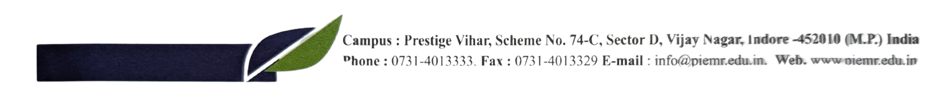

In [ ]:
xs